# Week 2 - Exploratory Data Analysis (EDA)
## Food Delivery Operations

This notebook explores delivery duration and how it varies across traffic, weather, distance, and vehicle type.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload the cleaned dataset from Week 1
uploaded = files.upload()

Saving cleaned_food_delivery.csv to cleaned_food_delivery.csv


In [2]:
# Load the cleaned dataset
df = pd.read_csv('cleaned_food_delivery.csv')

# Check the dataset size
print("Dataset shape:", df.shape)

# Display the first five records
df.head()

Dataset shape: (45584, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [3]:
# Check the delivery duration column
print(df['Time_taken (min)'].info())

# Check basic statistics
df['Time_taken (min)'].describe()

<class 'pandas.core.series.Series'>
RangeIndex: 45584 entries, 0 to 45583
Series name: Time_taken (min)
Non-Null Count  Dtype
--------------  -----
45584 non-null  int64
dtypes: int64(1)
memory usage: 356.3 KB
None


,Time_taken (min)
count,45584.000000
mean,26.293963
std,9.384298
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


In [4]:
duration = df['Time_taken (min)']

baseline = pd.DataFrame({
    'Metric': [
        'Count',
        'Mean',
        'Median',
        'Minimum',
        'Maximum',
        '25th Percentile',
        '75th Percentile',
        'Standard Deviation'
    ],
    'Value': [
        duration.count(),
        duration.mean(),
        duration.median(),
        duration.min(),
        duration.max(),
        duration.quantile(0.25),
        duration.quantile(0.75),
        duration.std()
    ]
})

baseline['Value'] = baseline['Value'].round(2)

baseline

,Metric,Value
0,Count,45584.00
1,Mean,26.29
2,Median,26.00
3,Minimum,10.00
4,Maximum,54.00
5,25th Percentile,19.00
6,75th Percentile,32.00
7,Standard Deviation,9.38


In [5]:
# Check skewness
print("Skewness:", duration.skew().round(2))

# Calculate IQR
Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)
IQR = Q3 - Q1

# Calculate possible outlier limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

# Count possible outliers
outliers = duration[
    (duration < lower_limit) | (duration > upper_limit)
]

print("Possible outliers:", len(outliers))

Skewness: 0.49
IQR: 13.0
Lower limit: -0.5
Upper limit: 51.5
Possible outliers: 270


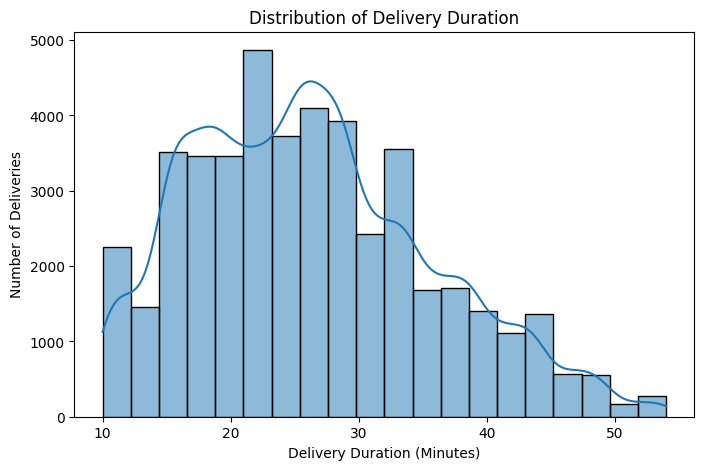

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(duration, bins=20, kde=True)

plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (Minutes)")
plt.ylabel("Number of Deliveries")

plt.show()

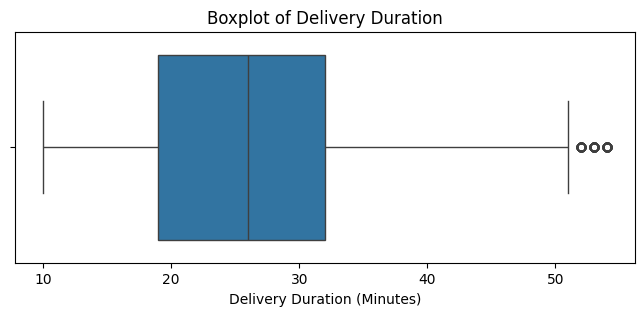

In [7]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=duration)

plt.title("Boxplot of Delivery Duration")
plt.xlabel("Delivery Duration (Minutes)")

plt.show()

### Baseline Interpretation

- The dataset contains 45,584 valid delivery records.
- The average delivery duration is 26.29 minutes, while the median is 26 minutes.
- The middle 50% of deliveries take between 19 and 32 minutes.
- The standard deviation is 9.38 minutes, showing variation in delivery duration.
- The distribution has a slight positive skewness of 0.49.
- The IQR method identified 270 possible outliers above 51.5 minutes. These records are retained because they may represent genuine longer deliveries.

## 2. Traffic Analysis

We compare delivery counts, average delivery duration, and median delivery duration across different traffic conditions to understand how delivery time varies with traffic density.

In [8]:
# Check available traffic categories
print(df['Road_traffic_density'].value_counts(dropna=False))

# Compare delivery duration across traffic categories
traffic_analysis = (
    df.groupby('Road_traffic_density')['Time_taken (min)']
    .agg(
        Delivery_Count='count',
        Mean_Duration='mean',
        Median_Duration='median'
    )
    .round(2)
    .reset_index()
)

traffic_analysis

Road_traffic_density
Low        15476
Jam        14139
Medium     10945
High        4423
Unknown      601
Name: count, dtype: int64


,Road_traffic_density,Delivery_Count,Mean_Duration,Median_Duration
0,High,4423,27.24,27.0
1,Jam,14139,31.18,31.0
2,Low,15476,21.27,20.0
3,Medium,10945,26.70,27.0
4,Unknown,601,26.54,26.0


### Traffic Analysis – Key Observation

Deliveries during Jam traffic had the highest average duration of 31.18 minutes (14,139 deliveries), while Low traffic had the lowest average duration of 21.27 minutes (15,476 deliveries). The difference was 9.91 minutes. This suggests that delivery duration is associated with traffic conditions. However, other factors may also influence delivery time.

## 3. Weather Analysis

We compare delivery counts, mean delivery duration, and median delivery duration across different weather conditions to understand how delivery time varies with weather.

In [9]:
# Check available weather categories
print(df['Weather_conditions'].value_counts(dropna=False))

# Compare delivery duration across weather categories
weather_analysis = (
    df.groupby('Weather_conditions')['Time_taken (min)']
    .agg(
        Delivery_Count='count',
        Mean_Duration='mean',
        Median_Duration='median'
    )
    .round(2)
    .reset_index()
)

weather_analysis

Weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
Unknown        616
Name: count, dtype: int64


,Weather_conditions,Delivery_Count,Mean_Duration,Median_Duration
0,Cloudy,7533,28.92,28.0
1,Fog,7653,28.91,28.0
2,Sandstorms,7494,25.88,26.0
3,Stormy,7584,25.87,26.0
4,Sunny,7282,21.86,20.0
5,Unknown,616,26.55,26.0
6,Windy,7422,26.12,26.0


### Weather Analysis – Key Observation

Cloudy weather had the highest average delivery duration of 28.92 minutes (7,533 deliveries), closely followed by Fog at 28.91 minutes (7,653 deliveries). Sunny weather had the lowest average duration of 21.86 minutes (7,282 deliveries). The difference between Cloudy and Sunny weather was 7.06 minutes. This indicates an association between weather conditions and delivery duration, but it does not prove that weather alone caused the difference.

## 4. Distance Analysis

The dataset contains restaurant and delivery coordinates but does not contain a direct distance column. Therefore, we calculate approximate straight-line distance in kilometers using the Haversine formula.

In [10]:
# Function to calculate distance between two coordinates
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in kilometers

    lat1, lon1, lat2, lon2 = np.radians([lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2) ** 2)

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


# Calculate approximate delivery distance
df['Distance_km'] = haversine(
    df['Restaurant_latitude'],
    df['Restaurant_longitude'],
    df['Delivery_location_latitude'],
    df['Delivery_location_longitude']
)

# Display sample distances
df[['Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude',
    'Distance_km',
    'Time_taken (min)']].head()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Distance_km,Time_taken (min)
0,30.327968,78.046106,30.397968,78.116106,10.280582,46
1,10.003064,76.307589,10.043064,76.347589,6.242319,23
2,18.562450,73.916619,18.652450,74.006619,13.787860,21
3,30.899584,75.809346,30.919584,75.829346,2.930258,20
4,26.463504,80.372929,26.593504,80.502929,19.396618,41


In [11]:
# Check distance statistics
print(df['Distance_km'].describe().round(2))

# Check unusually large distances
print("Distances above 50 km:",
      (df['Distance_km'] > 50).sum())

# Check missing distances
print("Missing distances:",
      df['Distance_km'].isnull().sum())

count    45584.00
mean        99.32
std       1099.84
min          1.47
25%          4.66
50%          9.26
75%         13.76
max      19692.67
Name: Distance_km, dtype: float64
Distances above 50 km: 431
Missing distances: 0


In [12]:
# Calculate correlation between distance and delivery duration
correlation = df['Distance_km'].corr(df['Time_taken (min)'])

print("Distance-Duration Correlation:", round(correlation, 3))

Distance-Duration Correlation: -0.003


In [13]:
# Inspect deliveries with distances above 50 km
unusual_distances = df[df['Distance_km'] > 50]

print("Number of unusual records:", len(unusual_distances))

unusual_distances[[
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude',
    'Distance_km',
    'Time_taken (min)'
]].head(10)

Number of unusual records: 431


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Distance_km,Time_taken (min)
83,-27.163303,78.057044,27.233303,78.127044,6048.631240,15
274,-27.165108,78.015053,27.225108,78.075053,6047.919478,31
280,-18.551440,-73.804855,18.611440,73.864855,16612.239055,12
416,-30.366322,-78.070453,30.496322,78.200453,17744.205087,20
525,-12.325461,-76.632278,12.385461,76.692278,17118.828366,16
574,-12.316967,76.603067,12.326967,76.613067,2740.280655,29
753,-23.359194,-85.325447,23.449194,85.415447,19070.337839,15
1050,-26.477750,-80.351569,26.487750,80.361569,18097.339322,15
1082,-15.546594,73.760431,15.606594,73.820431,3464.082720,29
1148,-12.337978,76.616792,12.387978,76.666792,2749.406397,33


In [14]:
# Count records with coordinates equal to 0.01
coordinate_check = pd.Series({
    'Restaurant latitude = 0.01':
        (df['Restaurant_latitude'] == 0.01).sum(),
    'Restaurant longitude = 0.01':
        (df['Restaurant_longitude'] == 0.01).sum(),
    'Delivery latitude = 0.01':
        (df['Delivery_location_latitude'] == 0.01).sum(),
    'Delivery longitude = 0.01':
        (df['Delivery_location_longitude'] == 0.01).sum()
})

coordinate_check

,0
Restaurant latitude = 0.01,0
Restaurant longitude = 0.01,0
Delivery latitude = 0.01,327
Delivery longitude = 0.01,327


In [15]:
# Identify suspicious coordinate records
invalid_coordinates = (
    (df['Restaurant_latitude'] <= 0.01) |
    (df['Restaurant_longitude'] <= 0.01) |
    (df['Delivery_location_latitude'] <= 0.01) |
    (df['Delivery_location_longitude'] <= 0.01)
)

print("Records with suspicious coordinates:",
      invalid_coordinates.sum())

print("Records with all coordinates above 0.01:",
      (~invalid_coordinates).sum())

# Check whether unusual distances have suspicious coordinates
print("Unusual distances with suspicious coordinates:",
      ((df['Distance_km'] > 50) & invalid_coordinates).sum())

print("Unusual distances with apparently positive coordinates:",
      ((df['Distance_km'] > 50) & (~invalid_coordinates)).sum())

Records with suspicious coordinates: 4071
Records with all coordinates above 0.01: 41513
Unusual distances with suspicious coordinates: 431
Unusual distances with apparently positive coordinates: 0


In [16]:
# Create a separate dataset for distance analysis
distance_df = df.loc[~invalid_coordinates].copy()

# Recalculate correlation using usable coordinate records
correlation = distance_df['Distance_km'].corr(
    distance_df['Time_taken (min)']
)

print("Records used:", len(distance_df))
print("Average distance:",
      round(distance_df['Distance_km'].mean(), 2), "km")
print("Median distance:",
      round(distance_df['Distance_km'].median(), 2), "km")
print("Maximum distance:",
      round(distance_df['Distance_km'].max(), 2), "km")

print("Distance-Duration Correlation:",
      round(correlation, 3))

Records used: 41513
Average distance: 9.72 km
Median distance: 9.19 km
Maximum distance: 20.97 km
Distance-Duration Correlation: 0.321


### Distance Analysis – Key Observation

The analysis used 41,513 records with apparently usable coordinates. The average calculated straight-line distance was 9.72 km, and the median was 9.19 km. The correlation between distance and delivery duration was +0.321, indicating a positive relationship. This suggests that longer-distance deliveries tend to have longer delivery durations. However, this relationship does not prove causation.

A total of 4,071 records were excluded from this distance analysis because at least one coordinate was 0.01 or below. The original dataset was not modified. The calculated distance represents straight-line distance, not actual road distance.

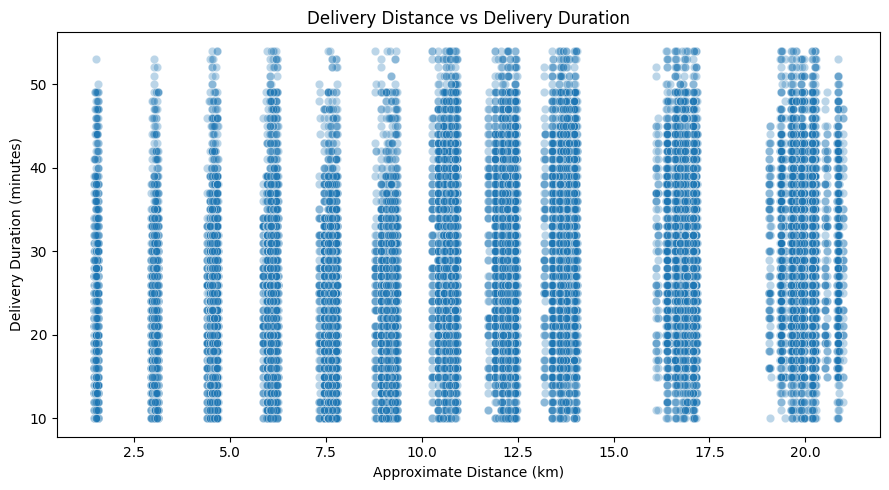

In [18]:
import os

# Create visualizations folder
os.makedirs('visualizations', exist_ok=True)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=distance_df,
    x='Distance_km',
    y='Time_taken (min)',
    alpha=0.3
)

plt.title('Delivery Distance vs Delivery Duration')
plt.xlabel('Approximate Distance (km)')
plt.ylabel('Delivery Duration (minutes)')

plt.tight_layout()

# Save the chart
plt.savefig(
    'visualizations/initial_distance_vs_duration.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 5. Vehicle Type Analysis

We compare delivery counts, mean delivery duration, and median delivery duration across vehicle types to understand how delivery duration varies by vehicle category.

In [20]:
print(df['Type_of_vehicle'].value_counts(dropna=False))

vehicle_analysis = (
    df.groupby('Type_of_vehicle')['Time_taken (min)']
    .agg(
        Delivery_Count='count',
        Mean_Duration='mean',
        Median_Duration='median'
    )
    .round(2)
    .reset_index()
)

vehicle_analysis

Type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68
Name: count, dtype: int64


,Type_of_vehicle,Delivery_Count,Mean_Duration,Median_Duration
0,bicycle,68,26.43,26.0
1,electric_scooter,3814,24.47,24.0
2,motorcycle,26429,27.61,26.0
3,scooter,15273,24.48,24.0


### Vehicle Type Analysis – Key Observation

Motorcycle deliveries had the highest average duration of 27.61 minutes across 26,429 deliveries. Scooter and electric scooter deliveries had similar average durations of 24.48 and 24.47 minutes, respectively. Bicycle deliveries had an average duration of 26.43 minutes, but only 68 records were available. These results show differences in delivery duration across vehicle types, although other factors may also influence the results.

In [21]:
print(df['multiple_deliveries'].value_counts(dropna=False))

multiple_analysis = (
    df.groupby('multiple_deliveries')['Time_taken (min)']
    .agg(
        Delivery_Count='count',
        Mean_Duration='mean',
        Median_Duration='median'
    )
    .round(2)
    .reset_index()
)

multiple_analysis

multiple_deliveries
1.0    29144
0.0    14094
2.0     1985
3.0      361
Name: count, dtype: int64


,multiple_deliveries,Delivery_Count,Mean_Duration,Median_Duration
0,0.0,14094,22.88,22.0
1,1.0,29144,26.72,26.0
2,2.0,1985,40.45,40.0
3,3.0,361,47.82,48.0


### Multiple Deliveries Analysis – Key Observation

Delivery duration increased with the number of multiple deliveries. Records with 0 multiple deliveries had the lowest average duration of 22.88 minutes (14,094 deliveries), while records with 3 multiple deliveries had the highest average duration of 47.82 minutes (361 deliveries). The difference was 24.94 minutes. This suggests that handling multiple deliveries is associated with longer delivery times. However, this analysis shows an association and does not prove causation.

In [22]:
df.columns.tolist()

['ID',
 'Delivery_person_ID',
 'Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Order_Date',
 'Time_Orderd',
 'Time_Order_picked',
 'Weather_conditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken (min)',
 'Distance_km']

### Partner Experience Analysis – Data Limitation

The dataset does not contain a delivery partner experience column. Therefore, partner experience analysis could not be performed. The dataset contains delivery person age, but age cannot be used as a substitute for work experience.

In [23]:
print(df['Delivery_person_Ratings'].describe())

print("\nRating counts:")
print(df['Delivery_person_Ratings'].value_counts().sort_index())

count    45584.000000
mean         4.636546
std          0.327931
min          1.000000
25%          4.600000
50%          4.700000
75%          4.800000
max          6.000000
Name: Delivery_person_Ratings, dtype: float64

Rating counts:
Delivery_person_Ratings
1.0      38
2.5      20
2.6      22
2.7      22
2.8      19
2.9      19
3.0       6
3.1      29
3.2      29
3.3      25
3.4      32
3.5     249
3.6     207
3.7     225
3.8     228
3.9     197
4.0    1077
4.1    1430
4.2    1418
4.3    1409
4.4    1360
4.5    3302
4.6    6938
4.7    9048
4.8    7146
4.9    7040
5.0    3996
6.0      53
Name: count, dtype: int64


In [24]:
# Check ratings below 1 or above 5
unusual_ratings = df[
    (df['Delivery_person_Ratings'] < 1) |
    (df['Delivery_person_Ratings'] > 5)
]

# Display the number of unusual records
print("Unusual rating records:", len(unusual_ratings))

# Display the unusual rating values and their counts
print(unusual_ratings['Delivery_person_Ratings'].value_counts())

Unusual rating records: 53
Delivery_person_Ratings
6.0    53
Name: count, dtype: int64


### Rating Analysis – Data Quality Observation

The average delivery person rating was 4.64, and the median was 4.7. Most ratings were between 4.0 and 5.0. However, 53 records contained a rating of 6.0, which is unusual if the intended rating scale is 1–5. These values are retained without modification because the original rating scale has not been verified.

In [25]:
# Group delivery records by rating and calculate delivery duration
rating_analysis = (
    df.groupby('Delivery_person_Ratings')['Time_taken (min)']
    .agg(
        Delivery_Count='count',
        Mean_Duration='mean',
        Median_Duration='median'
    )
    .round(2)
    .reset_index()
)

# Display the rating-wise delivery duration
rating_analysis

,Delivery_person_Ratings,Delivery_Count,Mean_Duration,Median_Duration
0,1.0,38,26.00,26.5
1,2.5,20,37.30,35.5
2,2.6,22,38.59,39.0
3,2.7,22,35.86,36.5
4,2.8,19,36.63,37.0
5,2.9,19,38.53,39.0
6,3.0,6,32.67,32.5
7,3.1,29,36.55,35.0
8,3.2,29,36.34,36.0
9,3.3,25,36.04,36.0


### Rating Analysis – Key Observation

Delivery records with ratings between 2.5 and 4.4 generally had higher average delivery durations than records with ratings between 4.5 and 5.0. For example, the average duration was 37.06 minutes for a rating of 3.5 (249 deliveries), compared with 23.64 minutes for a rating of 4.5 (3,302 deliveries). This shows an association between ratings and delivery duration. However, it does not establish a causal relationship. The unusual rating value of 6.0 is also retained without modification.

## 6. Key Findings Summary

The exploratory data analysis produced the following observations:

1. **Delivery Duration:** The average delivery duration was 26.29 minutes, while the median was 26 minutes. The distribution showed slight positive skewness (0.49).

2. **Traffic Conditions:** Deliveries during Jam traffic took an average of 31.18 minutes, compared with 21.27 minutes during Low traffic.

3. **Weather Conditions:** Cloudy weather had the highest average delivery duration of 28.92 minutes, while Sunny weather had the lowest at 21.86 minutes.

4. **Delivery Distance:** Distance had a positive correlation of 0.321 with delivery duration. Longer calculated distances generally showed longer delivery times.

5. **Vehicle Type:** Motorcycle deliveries had the highest average duration of 27.61 minutes, while scooter and electric scooter deliveries averaged around 24.5 minutes.

6. **Multiple Deliveries:** Average delivery duration increased from 22.88 minutes for 0 multiple deliveries to 47.82 minutes for 3 multiple deliveries.

7. **Delivery Ratings:** Records with ratings between 2.5 and 4.4 generally showed higher average delivery durations than records rated between 4.5 and 5.0.

### Data Limitations

- Partner experience information was not available in the dataset.
- 4,071 records were excluded from distance analysis because of suspicious coordinate values.
- Calculated distance represents straight-line distance, not actual road distance.
- 53 records contained an unusual rating value of 6.0. These values were retained without modification.
- The observed relationships do not necessarily indicate causation.

### Conclusion

The analysis suggests that traffic, weather, distance, vehicle type, multiple deliveries, and delivery ratings are associated with variations in delivery duration. These findings provide an initial understanding of food delivery operations and will help guide further visualization and recommendations.